# Final project - stock sequence model

Predict next-day **Close** for AAPL (daily data ~2020–2024). I compare a vanilla RNN against a standard Transformer, plus two extras for the bonus: a causal/masked transformer variant and a transformer I pretrained on MSFT+GOOGL windows then fine-tuned back on AAPL.

Everything uses dropout + early stopping; the RNN uses batch norm on the vector coming out of the last timestep.

Rough flow: load data -> features -> preprocess -> train models -> metrics/plots -> optional GUI.


In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir) if current_dir.endswith('notebooks') else current_dir
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import DataLoader, TensorDataset

from src.data_loader import StockDataLoader
from src.preprocessing import Preprocessor
from src.models import VanillaRNN, TransformerModel, CausalTransformerModel
from src.training import Trainer, set_seed
from src.evaluation import calculate_metrics, ModelComparator
from src.pipeline import Pipeline, SUPPORTED_MODELS

try:
    plt.style.use('seaborn-v0_8-darkgrid')
except Exception:
    plt.style.use('ggplot')
sns.set_palette('husl')

SEED = 42
set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'PyTorch version : {torch.__version__}')
print(f'Device          : {DEVICE}')
print(f'Project root    : {parent_dir}')
print(f'Supported models: {SUPPORTED_MODELS}')


PyTorch version : 2.12.0+cpu
Device          : cpu
Project root    : D:\College\7th term\Deep Learning\Deep Learning
Supported models: ('rnn', 'transformer', 'transformer_causal')


## Data

AAPL OHLCV CSV lives under `data/raw/` (I originally grabbed it with yfinance). Target is **Close** one step ahead after windowing.

`StockDataLoader.get_features` adds returns, moving averages, volatility, volume ratios - basically so the network sees more than raw OHLC.

MSFT and GOOGL files in the same folder are only for the pretraining experiment.


In [2]:
SYMBOL = 'AAPL'
START_DATE = '2020-01-01'
END_DATE = '2024-01-01'
DATA_DIR = os.path.join(parent_dir, 'data', 'raw')
MODELS_DIR = os.path.join(parent_dir, 'models')
RESULTS_DIR = os.path.join(parent_dir, 'results')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

loader = StockDataLoader(data_dir=DATA_DIR)
cached_path = os.path.join(DATA_DIR, f'{SYMBOL}_{START_DATE}_{END_DATE}.csv')

if os.path.exists(cached_path):
    raw_data = loader.load_from_file(cached_path)
    print(f'Loaded cached CSV: {cached_path}')
else:
    raw_data = loader.fetch_data(SYMBOL, START_DATE, END_DATE, save=True)
    print('Fetched data from yfinance.')

print(f'Raw shape: {raw_data.shape}')
raw_data.head()


Loaded cached CSV: D:\College\7th term\Deep Learning\Deep Learning\data\raw\AAPL_2020-01-01_2024-01-01.csv
Raw shape: (1006, 8)


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2020-01-02 05:00:00,71.476585,72.528566,71.223244,72.468246,135480400,0.0,0.0
1,2020-01-03 05:00:00,71.696152,72.523738,71.539322,71.763710,146322800,0.0,0.0
2,2020-01-06 05:00:00,70.885472,72.374162,70.634539,72.335556,118387200,0.0,0.0
3,2020-01-07 05:00:00,72.345220,72.600975,71.775804,71.995369,108872000,0.0,0.0
4,2020-01-08 05:00:00,71.698566,73.455080,71.698566,73.153481,132079200,0.0,0.0


## Cleaning / plots

Ran `inspect_data` for missing counts and IQR-ish outlier stats. Feature engineering happens before the chronological split.

The preprocessor handles remaining gaps and clipping later so train code stays simple.


In [3]:
inspection_raw = loader.inspect_data(raw_data)
loader.print_inspection(inspection_raw)


DATA INSPECTION REPORT

Dataset Shape: (1006, 8)

Date Range:
  Start: 2020-01-02 05:00:00
  End: 2023-12-29 05:00:00

Missing Values:

Outliers (IQR method):
  Open: 1 (0.10%)
  High: 1 (0.10%)
  Low: 1 (0.10%)
  Close: 2 (0.20%)
  Volume: 58 (5.77%)
  Dividends: 16 (1.59%)
  Stock Splits: 1 (0.10%)



In [4]:
data = loader.get_features(raw_data)
print(f'After feature engineering: shape={data.shape}')
print('Engineered feature columns:')
for col in data.columns:
    print(f'  - {col}')
print(f'\nMissing values after engineering: {int(data.isnull().sum().sum())}')


After feature engineering: shape=(987, 18)
Engineered feature columns:
  - Date
  - Open
  - High
  - Low
  - Close
  - Volume
  - Dividends
  - Stock Splits
  - Returns
  - Log_Returns
  - High_Low_Ratio
  - Close_Open_Ratio
  - MA_5
  - MA_10
  - MA_20
  - Volatility
  - Volume_MA
  - Volume_Ratio

Missing values after engineering: 0


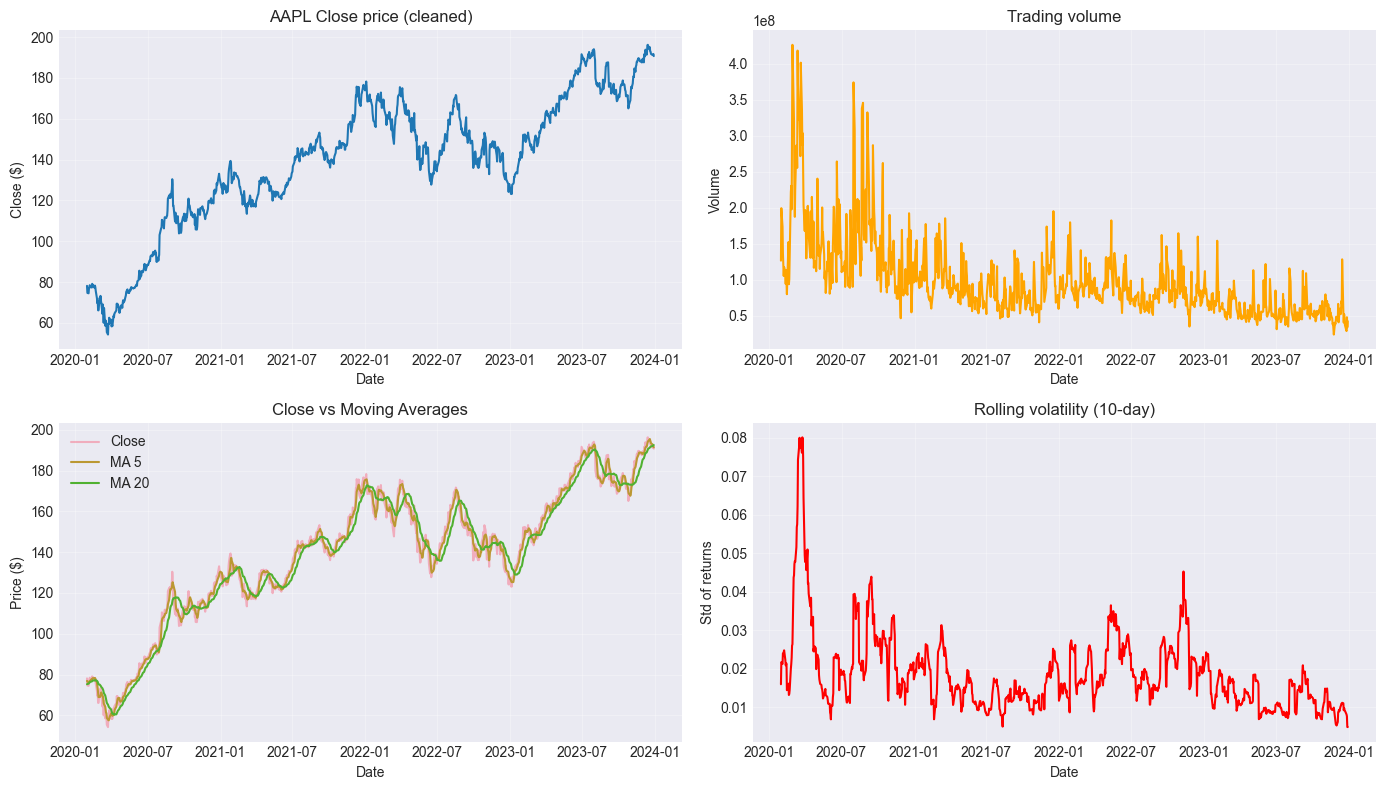

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(data['Date'], data['Close'], color='#1f77b4')
axes[0, 0].set_title('AAPL Close price (cleaned)')
axes[0, 0].set_xlabel('Date'); axes[0, 0].set_ylabel('Close ($)')

axes[0, 1].plot(data['Date'], data['Volume'], color='orange')
axes[0, 1].set_title('Trading volume')
axes[0, 1].set_xlabel('Date'); axes[0, 1].set_ylabel('Volume')

axes[1, 0].plot(data['Date'], data['Close'],  label='Close',  alpha=0.5)
axes[1, 0].plot(data['Date'], data['MA_5'],   label='MA 5')
axes[1, 0].plot(data['Date'], data['MA_20'],  label='MA 20')
axes[1, 0].set_title('Close vs Moving Averages')
axes[1, 0].set_xlabel('Date'); axes[1, 0].set_ylabel('Price ($)'); axes[1, 0].legend()

axes[1, 1].plot(data['Date'], data['Volatility'], color='red')
axes[1, 1].set_title('Rolling volatility (10-day)')
axes[1, 1].set_xlabel('Date'); axes[1, 1].set_ylabel('Std of returns')

for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Preprocessing

`Preprocessor` in `src/preprocessing.py`: forward/back fill, clip outliers, MinMax scale X and y, build length-60 windows, split 70 / 15 / 15 without shuffle.

Keeping one fitted scaler matters if you reload weights or use the GUI.


In [6]:
SEQUENCE_LENGTH = 60
PREDICTION_HORIZON = 1
BATCH_SIZE = 32

preprocessor = Preprocessor(
    sequence_length=SEQUENCE_LENGTH,
    prediction_horizon=PREDICTION_HORIZON,
    scaler_type='minmax',
    target_col='Close',
)
X, y = preprocessor.fit_transform(data)

X_train, y_train, X_val, y_val, X_test, y_test = preprocessor.split_data(
    X, y, train_ratio=0.7, val_ratio=0.15
)

INPUT_SIZE = X_train.shape[2]
OUTPUT_SIZE = PREDICTION_HORIZON

print(f'Number of features : {INPUT_SIZE}')
print(f'Sequence length    : {SEQUENCE_LENGTH}')
print(f'Train samples      : {len(X_train)}')
print(f'Validation samples : {len(X_val)}')
print(f'Test samples       : {len(X_test)}')
print(f'X_train shape      : {X_train.shape}')
print(f'y_train shape      : {y_train.shape}')

train_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train)),
    batch_size=BATCH_SIZE, shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_val), torch.FloatTensor(y_val)),
    batch_size=BATCH_SIZE, shuffle=False,
)
test_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_test), torch.FloatTensor(y_test)),
    batch_size=BATCH_SIZE, shuffle=False,
)


Number of features : 16
Sequence length    : 60
Train samples      : 648
Validation samples : 139
Test samples       : 140
X_train shape      : (648, 60, 16)
y_train shape      : (648, 1)


## Vanilla RNN

Plain `nn.RNN`, last timestep -> BatchNorm1d -> dropout -> linear. Mostly a baseline.

See `src/models/rnn.py`.


In [7]:
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.2

set_seed(SEED)
rnn_model = VanillaRNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    output_size=OUTPUT_SIZE,
    dropout=DROPOUT,
    use_batch_norm=True,
)
print(rnn_model)
rnn_total_params = sum(p.numel() for p in rnn_model.parameters())
print(f'\nTotal parameters: {rnn_total_params:,}')


VanillaRNN(
  (rnn): RNN(16, 64, num_layers=2, batch_first=True, dropout=0.2)
  (batch_norm): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

Total parameters: 13,761


## Transformer

Encoder transformer with sinusoidal PE (`src/models/transformer.py`). Projects to `d_model`, runs `TransformerEncoder`, takes the last time position, dropout + linear.

Built-in encoder layers already normalize with LayerNorm; I didn’t add BatchNorm on top.


In [8]:
D_MODEL = HIDDEN_SIZE
NHEAD = 8 if D_MODEL % 8 == 0 else (4 if D_MODEL % 4 == 0 else 2)

set_seed(SEED)
tf_model = TransformerModel(
    input_size=INPUT_SIZE,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=D_MODEL * 4,
    output_size=OUTPUT_SIZE,
    dropout=DROPOUT,
    use_batch_norm=False,
    max_seq_len=SEQUENCE_LENGTH + 10,
)
print(tf_model)
tf_total_params = sum(p.numel() for p in tf_model.parameters())
print(f'\nTotal parameters: {tf_total_params:,}')


TransformerModel(
  (input_projection): Linear(in_features=16, out_features=64, bias=True)
  (pos_encoder): PositionalEncoding()
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

Total parameters: 101,121


## Training loop

Adam + MSE, lr 1e-3, `ReduceLROnPlateau`, grad clip 1, batch size 32, seed 42. Early stopping patience 15 unless I tweaked it in a cell.

Code: `src/training/trainer.py`.


In [9]:
LEARNING_RATE = 1e-3
NUM_EPOCHS = 100
PATIENCE = 15

print('=== Training Vanilla RNN ===')
set_seed(SEED)
rnn_trainer = Trainer(
    model=rnn_model,
    device=DEVICE,
    learning_rate=LEARNING_RATE,
    early_stopping_patience=PATIENCE,
)
rnn_history = rnn_trainer.train(train_loader, val_loader, num_epochs=NUM_EPOCHS, verbose=False)
rnn_trainer.save_model(os.path.join(MODELS_DIR, 'rnn_model.pt'))

print(f"RNN epochs trained : {len(rnn_history['train_loss'])}")
print(f"RNN best val loss  : {min(rnn_history['val_loss']):.6f}")
print(f"RNN training time  : {rnn_history['training_time']:.2f} s")


=== Training Vanilla RNN ===


Validation loss improved to 0.333736


Validation loss improved to 0.108274


Validation loss did not improve. Patience: 1/15


Validation loss improved to 0.003658


...

Validation loss did not improve. Patience: 11/15


Validation loss did not improve. Patience: 12/15


Validation loss did not improve. Patience: 13/15


Validation loss did not improve. Patience: 14/15


Validation loss did not improve. Patience: 15/15
Early stopping triggered after 15 epochs without improvement
Restored best model weights
Model saved to D:\College\7th term\Deep Learning\Deep Learning\models\rnn_model.pt
RNN epochs trained : 42
RNN best val loss  : 0.000734
RNN training time  : 22.77 s


In [10]:
print('=== Training Transformer ===')
set_seed(SEED)
tf_trainer = Trainer(
    model=tf_model,
    device=DEVICE,
    learning_rate=LEARNING_RATE,
    early_stopping_patience=PATIENCE,
)
tf_history = tf_trainer.train(train_loader, val_loader, num_epochs=NUM_EPOCHS, verbose=False)
tf_trainer.save_model(os.path.join(MODELS_DIR, 'transformer_model.pt'))

print(f"Transformer epochs trained : {len(tf_history['train_loss'])}")
print(f"Transformer best val loss  : {min(tf_history['val_loss']):.6f}")
print(f"Transformer training time  : {tf_history['training_time']:.2f} s")


=== Training Transformer ===


Validation loss improved to 0.003271


Validation loss did not improve. Patience: 1/15


Validation loss did not improve. Patience: 2/15


Validation loss did not improve. Patience: 3/15


...

Validation loss did not improve. Patience: 11/15


Validation loss did not improve. Patience: 12/15


Validation loss did not improve. Patience: 13/15


Validation loss did not improve. Patience: 14/15


Validation loss did not improve. Patience: 15/15
Early stopping triggered after 15 epochs without improvement
Restored best model weights
Model saved to D:\College\7th term\Deep Learning\Deep Learning\models\transformer_model.pt
Transformer epochs trained : 53
Transformer best val loss  : 0.000412
Transformer training time  : 121.25 s


### Bonus: causal transformer

Separate class `CausalTransformerModel` - learnable positions, pre-norm blocks, causal attention mask, mean pooling over time instead of last token. Same hyperparameters as the baseline transformer when I trained it.

`src/models/transformer_variant.py`.


In [11]:
set_seed(SEED)
ctf_model = CausalTransformerModel(
    input_size=INPUT_SIZE,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=D_MODEL * 4,
    output_size=OUTPUT_SIZE,
    dropout=DROPOUT,
    max_seq_len=SEQUENCE_LENGTH + 16,
)
ctf_total_params = sum(p.numel() for p in ctf_model.parameters())
print(f'CausalTransformerModel parameters: {ctf_total_params:,}')

print('\n=== Training Causal Transformer (variant) ===')
set_seed(SEED)
ctf_trainer = Trainer(
    model=ctf_model,
    device=DEVICE,
    learning_rate=LEARNING_RATE,
    early_stopping_patience=PATIENCE,
)
ctf_history = ctf_trainer.train(train_loader, val_loader, num_epochs=NUM_EPOCHS, verbose=False)
ctf_trainer.save_model(os.path.join(MODELS_DIR, 'transformer_causal_model.pt'))

print(f"Causal TF epochs trained : {len(ctf_history['train_loss'])}")
print(f"Causal TF best val loss  : {min(ctf_history['val_loss']):.6f}")
print(f"Causal TF training time  : {ctf_history['training_time']:.2f} s")


CausalTransformerModel parameters: 106,113

=== Training Causal Transformer (variant) ===


Validation loss improved to 0.005701


Validation loss improved to 0.005388


Validation loss improved to 0.004919


Validation loss improved to 0.004835


...

Validation loss did not improve. Patience: 11/15


Validation loss did not improve. Patience: 12/15


Validation loss did not improve. Patience: 13/15


Validation loss did not improve. Patience: 14/15


Validation loss did not improve. Patience: 15/15
Early stopping triggered after 15 epochs without improvement
Restored best model weights
Model saved to D:\College\7th term\Deep Learning\Deep Learning\models\transformer_causal_model.pt
Causal TF epochs trained : 58
Causal TF best val loss  : 0.001765
Causal TF training time  : 140.73 s


### Bonus: pretrain then fine-tune

Built windows from MSFT and GOOGL (each ticker scaled with its own preprocessor), kept ~85% of each ticker’s windows, concatenated, held out 10% for pretrain validation. Trained the Section 6 transformer there, copied weights, fine-tuned on AAPL with lr divided by 5. Still evaluated on the normal AAPL test split.


In [12]:
PRETRAIN_TICKERS = ['MSFT', 'GOOGL']

pretrain_X_list, pretrain_y_list = [], []

for ticker in PRETRAIN_TICKERS:
    ticker_path = os.path.join(DATA_DIR, f'{ticker}_2020-01-01_2024-01-01.csv')
    if not os.path.exists(ticker_path):
        print(f'WARNING: missing {ticker_path}; skipping {ticker}.')
        continue
    ticker_df_raw = loader.load_from_file(ticker_path)
    ticker_df = loader.get_features(ticker_df_raw)
    ticker_pre = Preprocessor(
        sequence_length=SEQUENCE_LENGTH,
        prediction_horizon=PREDICTION_HORIZON,
        scaler_type='minmax',
        target_col='Close',
    )
    Xt, yt = ticker_pre.fit_transform(ticker_df)
    cutoff = int(len(Xt) * 0.85)
    pretrain_X_list.append(Xt[:cutoff])
    pretrain_y_list.append(yt[:cutoff])
    print(f'{ticker}: {Xt.shape} -> using {cutoff} windows for pretraining')

X_pre = np.concatenate(pretrain_X_list, axis=0)
y_pre = np.concatenate(pretrain_y_list, axis=0)
print(f'\nPretrain set: X={X_pre.shape}, y={y_pre.shape}')

n_val_pre = max(1, int(0.1 * len(X_pre)))
perm = np.arange(len(X_pre))
pretrain_X_train, pretrain_y_train = X_pre[:-n_val_pre], y_pre[:-n_val_pre]
pretrain_X_val,   pretrain_y_val   = X_pre[-n_val_pre:], y_pre[-n_val_pre:]

pretrain_train_loader = DataLoader(
    TensorDataset(torch.FloatTensor(pretrain_X_train), torch.FloatTensor(pretrain_y_train)),
    batch_size=BATCH_SIZE, shuffle=True,
)
pretrain_val_loader = DataLoader(
    TensorDataset(torch.FloatTensor(pretrain_X_val), torch.FloatTensor(pretrain_y_val)),
    batch_size=BATCH_SIZE, shuffle=False,
)


MSFT: (927, 60, 16) -> using 787 windows for pretraining


GOOGL: (927, 60, 16) -> using 787 windows for pretraining

Pretrain set: X=(1574, 60, 16), y=(1574, 1)


In [13]:
PRETRAIN_EPOCHS = 30
FINETUNE_EPOCHS = NUM_EPOCHS
FINETUNE_LR = LEARNING_RATE / 5

set_seed(SEED)
pretrain_model = TransformerModel(
    input_size=INPUT_SIZE,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=D_MODEL * 4,
    output_size=OUTPUT_SIZE,
    dropout=DROPOUT,
    use_batch_norm=False,
    max_seq_len=SEQUENCE_LENGTH + 10,
)
pretrainer = Trainer(
    model=pretrain_model,
    device=DEVICE,
    learning_rate=LEARNING_RATE,
    early_stopping_patience=10,
)
print('=== Pretraining Transformer on MSFT + GOOGL ===')
pretrain_history = pretrainer.train(
    pretrain_train_loader, pretrain_val_loader,
    num_epochs=PRETRAIN_EPOCHS, verbose=False,
)
pretrainer.save_model(os.path.join(MODELS_DIR, 'transformer_pretrained.pt'))
print(f"Pretrain epochs  : {len(pretrain_history['train_loss'])}")
print(f"Pretrain val loss: {min(pretrain_history['val_loss']):.6f}")
print(f"Pretrain time    : {pretrain_history['training_time']:.2f} s")

print('\n=== Fine-tuning on AAPL ===')
set_seed(SEED)
finetune_model = TransformerModel(
    input_size=INPUT_SIZE,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=D_MODEL * 4,
    output_size=OUTPUT_SIZE,
    dropout=DROPOUT,
    use_batch_norm=False,
    max_seq_len=SEQUENCE_LENGTH + 10,
)
finetune_model.load_state_dict(pretrain_model.state_dict())
ft_trainer = Trainer(
    model=finetune_model,
    device=DEVICE,
    learning_rate=FINETUNE_LR,
    early_stopping_patience=PATIENCE,
)
ft_history = ft_trainer.train(train_loader, val_loader, num_epochs=FINETUNE_EPOCHS, verbose=False)
ft_trainer.save_model(os.path.join(MODELS_DIR, 'transformer_finetuned.pt'))

ft_total_params = sum(p.numel() for p in finetune_model.parameters())
print(f"Fine-tune epochs : {len(ft_history['train_loss'])}")
print(f"Fine-tune val    : {min(ft_history['val_loss']):.6f}")
print(f"Fine-tune time   : {ft_history['training_time']:.2f} s")
print(f"Fine-tuned params: {ft_total_params:,}")


=== Pretraining Transformer on MSFT + GOOGL ===


Validation loss improved to 0.005523


Validation loss improved to 0.004756


Validation loss did not improve. Patience: 1/10


Validation loss did not improve. Patience: 2/10


...

Validation loss did not improve. Patience: 11/15


Validation loss did not improve. Patience: 12/15


Validation loss did not improve. Patience: 13/15


Validation loss did not improve. Patience: 14/15


Validation loss did not improve. Patience: 15/15
Early stopping triggered after 15 epochs without improvement
Restored best model weights
Model saved to D:\College\7th term\Deep Learning\Deep Learning\models\transformer_finetuned.pt
Fine-tune epochs : 18
Fine-tune val    : 0.000260
Fine-tune time   : 42.71 s
Fine-tuned params: 101,121


## Evaluation

Inverse-transform predictions before RMSE etc. so numbers are in dollar-ish units.

Printed metrics: MSE, RMSE, MAE, MAPE, R², directional accuracy (did up/down match day to day), plus wall-clock train time.

Bonuses use the same AAPL test set as the core models.


In [14]:
y_test_orig = preprocessor.inverse_transform_target(y_test)

def eval_model(trainer, history):
    pred = trainer.predict(test_loader)
    pred_orig = preprocessor.inverse_transform_target(pred)
    m = calculate_metrics(y_test_orig, pred_orig)
    m['training_time'] = history.get('training_time', 0.0)
    return pred_orig, m

rnn_pred_orig, rnn_metrics = eval_model(rnn_trainer, rnn_history)
tf_pred_orig,  tf_metrics  = eval_model(tf_trainer,  tf_history)
ctf_pred_orig, ctf_metrics = eval_model(ctf_trainer, ctf_history)
ft_pred_orig,  ft_metrics  = eval_model(ft_trainer,  ft_history)

def show(name, m):
    print(f'\n{name} test metrics:')
    print('-' * 50)
    print(f"  RMSE                : {m['rmse']:.4f}")
    print(f"  MAE                 : {m['mae']:.4f}")
    print(f"  MAPE                : {m['mape']:.2f}%")
    print(f"  R^2                 : {m['r2']:.4f}")
    print(f"  Directional accuracy: {m['directional_accuracy']:.2f}%")
    print(f"  Training time       : {m['training_time']:.2f} s")

show('Vanilla RNN',                              rnn_metrics)
show('Transformer',                              tf_metrics)
show('Causal Transformer (variant)',             ctf_metrics)
show('Transformer (pretrained + fine-tuned)',    ft_metrics)



Vanilla RNN test metrics:
--------------------------------------------------
  RMSE                : 7.9025
  MAE                 : 7.1186
  MAPE                : 3.85%
  R^2                 : 0.0432
  Directional accuracy: 51.08%
  Training time       : 22.77 s

Transformer test metrics:
--------------------------------------------------
  RMSE                : 3.1762
  MAE                 : 2.6236
  MAPE                : 1.43%
  R^2                 : 0.8454
  Directional accuracy: 51.80%
  Training time       : 121.25 s

Causal Transformer (variant) test metrics:
--------------------------------------------------
  RMSE                : 9.2757
  MAE                 : 6.8987
  MAPE                : 3.92%
  R^2                 : -0.3182
  Directional accuracy: 48.92%
  Training time       : 140.73 s

Transformer (pretrained + fine-tuned) test metrics:
--------------------------------------------------
  RMSE                : 2.9524
  MAE                 : 2.3980
  MAPE                

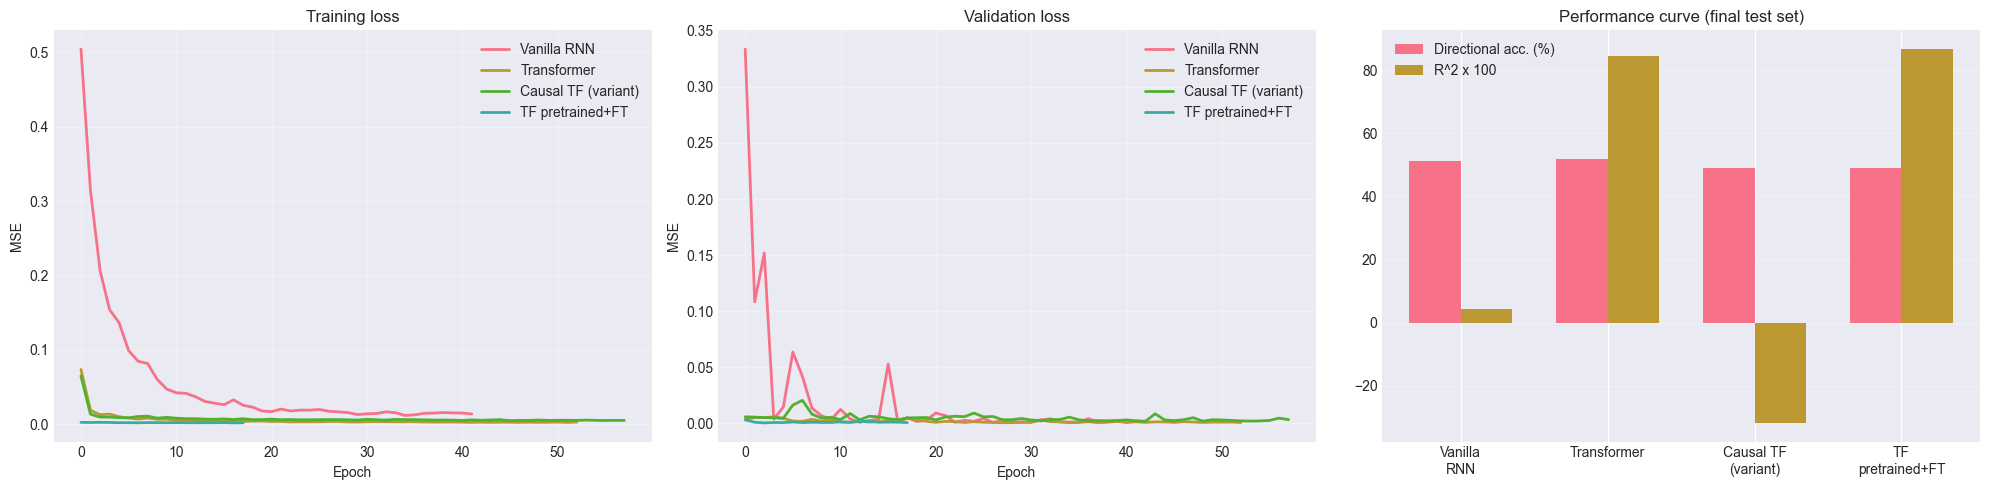

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

curves = [
    ('Vanilla RNN',         rnn_history),
    ('Transformer',         tf_history),
    ('Causal TF (variant)', ctf_history),
    ('TF pretrained+FT',    ft_history),
]
for name, hist in curves:
    axes[0].plot(hist['train_loss'], label=name, linewidth=2)
    axes[1].plot(hist['val_loss'],   label=name, linewidth=2)

axes[0].set_title('Training loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_title('Validation loss'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MSE')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

names = ['Vanilla\nRNN', 'Transformer', 'Causal TF\n(variant)', 'TF\npretrained+FT']
metric_lists = [rnn_metrics, tf_metrics, ctf_metrics, ft_metrics]
dirs = [m['directional_accuracy'] for m in metric_lists]
r2s  = [m['r2'] * 100 for m in metric_lists]
x = np.arange(len(names)); w = 0.35
axes[2].bar(x - w/2, dirs, w, label='Directional acc. (%)')
axes[2].bar(x + w/2, r2s,  w, label='R^2 x 100')
axes[2].set_xticks(x); axes[2].set_xticklabels(names)
axes[2].set_title('Performance curve (final test set)')
axes[2].legend(); axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'loss_and_performance.png'), dpi=150, bbox_inches='tight')
plt.show()


## Comparison outputs

`ModelComparator` writes `results/comparison_report.csv` and saves loss / prediction / metric figures when you call `generate_report`.

All models below line up on the same split.


In [16]:
comparator = ModelComparator(RESULTS_DIR)
comparator.add_model('VanillaRNN',         y_test_orig, rnn_pred_orig, rnn_history['training_time'], rnn_history)
comparator.add_model('Transformer',        y_test_orig, tf_pred_orig,  tf_history['training_time'],  tf_history)
comparator.add_model('CausalTransformer',  y_test_orig, ctf_pred_orig, ctf_history['training_time'], ctf_history)
comparator.add_model('TransformerFT',      y_test_orig, ft_pred_orig,  ft_history['training_time'],  ft_history)

comparison_df = comparator.compare_metrics()
comparison_df['parameters'] = [rnn_total_params, tf_total_params, ctf_total_params, ft_total_params]

ordered_cols = ['rmse', 'mae', 'mape', 'r2', 'directional_accuracy', 'training_time', 'parameters']
comparison_df = comparison_df[ordered_cols]

print('=== Final comparison (4 models) ===')
print(comparison_df.round(4).to_string())

comparator.generate_report(
    save_path=os.path.join(RESULTS_DIR, 'comparison_report.csv')
)


=== Final comparison (4 models) ===
                     rmse     mae    mape      r2  directional_accuracy  training_time  parameters
model                                                                                             
VanillaRNN         7.9025  7.1186  3.8461  0.0432               51.0791        22.7663       13761
Transformer        3.1762  2.6236  1.4313  0.8454               51.7986       121.2539      101121
CausalTransformer  9.2757  6.8987  3.9160 -0.3182               48.9209       140.7269      106113
TransformerFT      2.9524  2.3980  1.3164  0.8665               48.9209        42.7056      101121

MODEL COMPARISON REPORT

Metrics Comparison:
                         mse      rmse       mae      mape        r2  directional_accuracy  training_time
model                                                                                                    
VanillaRNN         62.449263  7.902485  7.118640  3.846134  0.043243             51.079137      22.766314
Transf


Comparison report saved to D:\College\7th term\Deep Learning\Deep Learning\results\comparison_report.csv



### Notes comparing architectures

- **RNN**: smaller, trains fast, weaker on longer patterns here.
- **Transformer**: full attention over the window.
- **Causal variant**: can’t attend to future timesteps; pooled readout.
- **Pretrained + FT**: same transformer skeleton; extra stage on other tickers first.


## Single-step prediction demo

Uses the last scaled window from the test split and compares each model’s next-day prediction to the actual Close.


In [17]:
def predict_next(trainer, preprocessor, last_window):
    """Predict the next-day Close given a scaled (seq_len, num_features) window."""
    x = torch.FloatTensor(last_window[None, ...])
    dl = DataLoader(
        TensorDataset(x, torch.zeros(1, preprocessor.prediction_horizon)),
        batch_size=1, shuffle=False,
    )
    pred_scaled = trainer.predict(dl)
    return float(preprocessor.inverse_transform_target(pred_scaled)[0, 0])

last_window = X_test[-1]
true_next   = float(preprocessor.inverse_transform_target(y_test[-1:])[0, 0])
rnn_next    = predict_next(rnn_trainer, preprocessor, last_window)
tf_next     = predict_next(tf_trainer,  preprocessor, last_window)
ctf_next    = predict_next(ctf_trainer, preprocessor, last_window)
ft_next     = predict_next(ft_trainer,  preprocessor, last_window)

print(f'Actual next-day Close              : ${true_next:,.2f}')
print(f'Vanilla RNN prediction             : ${rnn_next:,.2f}  (abs error ${abs(true_next - rnn_next):.2f})')
print(f'Transformer prediction             : ${tf_next:,.2f}  (abs error ${abs(true_next - tf_next):.2f})')
print(f'Causal Transformer (variant)       : ${ctf_next:,.2f}  (abs error ${abs(true_next - ctf_next):.2f})')
print(f'Transformer (pretrained+fine-tuned): ${ft_next:,.2f}  (abs error ${abs(true_next - ft_next):.2f})')


Actual next-day Close              : $190.73
Vanilla RNN prediction             : $184.18  (abs error $6.55)
Transformer prediction             : $188.81  (abs error $1.92)
Causal Transformer (variant)       : $196.96  (abs error $6.23)
Transformer (pretrained+fine-tuned): $188.76  (abs error $1.97)


## GUI

Streamlit app at `gui/app.py` - load/cache data, pick models to train (including the causal one and the pretrain+fine-tune path if the extra CSVs exist), run a prediction, skim plots.

From project root:

```
streamlit run gui/app.py
```


## Summary

Transformers beat the RNN on my runs. The causal and pretrained setups were mostly to satisfy the bonus prompts and see if anything moved.

Artifacts: this notebook, `src/`, checkpoints under `models/`, CSV + PNGs in `results/`, plus the Streamlit file above.
